# Formations, angular role features and change detection

Implement the requested distribution plots, Pleuler-inspired viewpoint counts and fixed-template prediction.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## Raw and centroid-normalized distributions
Subtract the outfield team centroid at each frame. Plot means and covariance ellipses using identical samples. Two-standard-deviation axes describe dispersion, not a confidence interval. Metadata role names are assigned positions, not verified frame-level roles. [Pleuler: Fixed to Fluid](https://github.com/devinpleuler/research/blob/master/frame-by-frame-position.md).

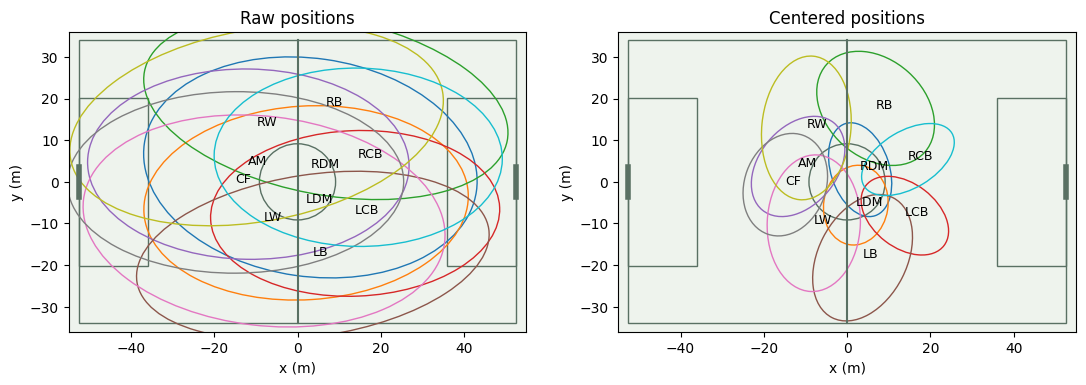

In [2]:
from matplotlib.patches import Ellipse
team=observed[observed.team_id.eq(1802)&~observed.player_id.isin(keepers)].copy()
team[['cx','cy']]=team[['x','y']].to_numpy()-team.groupby(['period_id','frame_id'])[['x','y']].transform('mean').to_numpy()
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,cols,title in zip(axs,[['x','y'],['cx','cy']],['Raw positions','Centered positions']):
    pitch(ax);ax.set_title(title)
    for i,(pid,g) in enumerate(team.groupby('player_id')):
        points=g[cols].to_numpy();mean=points.mean(axis=0)
        vals,vecs=np.linalg.eigh(np.cov(points.T));v=vecs[:,-1]
        ax.add_patch(Ellipse(mean,4*np.sqrt(vals[-1]),4*np.sqrt(vals[0]),angle=np.degrees(np.arctan2(v[1],v[0])),fill=False,color=plt.cm.tab10(i%10)))
        ax.text(*mean,role_labels[pid],fontsize=9)
plt.show()

## Manufacture angular count features
For a given player, compute relative angles to every other player. Sweep 24 headings and count objects inside a 90° sector. Rotate both axes for attack-left teams. Pleuler's original method counts teammates; the opponent channel is our extension. This models relative geometry, not gaze or occluded vision.

,player_id,metadata_role,mate_0,mate_1,mate_2,mate_3,mate_4,mate_5,mate_6,mate_7
0,11897,RB,1,1,0,0,0,0,0,0
1,287934,RDM,2,2,2,1,1,2,1,2
2,50982,LB,0,1,1,3,4,5,8,8
3,50999,GK,0,0,0,0,0,0,0,1
4,51002,LDM,5,4,4,2,3,3,3,3


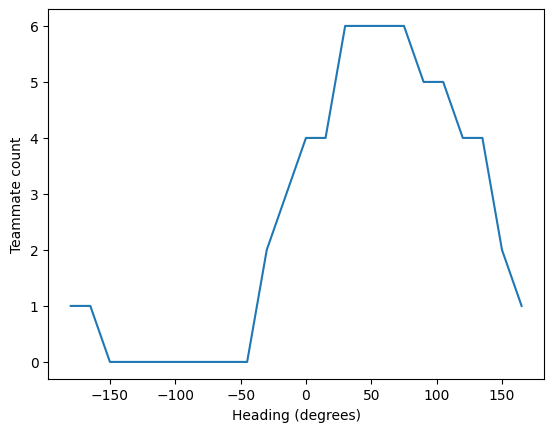

In [3]:
def angular_counts(nodes,pid,attack_sign=1,bins=24,fov=90):
    p=nodes[nodes.player_id.eq(pid)].iloc[0]
    others=nodes[~nodes.player_id.eq(pid)]
    delta=attack_sign*(others[['x','y']].to_numpy()-p[['x','y']].to_numpy(dtype=float))
    angles=np.arctan2(delta[:,1],delta[:,0]);headings=np.linspace(-np.pi,np.pi,bins,endpoint=False)
    difference=np.angle(np.exp(1j*(angles[:,None]-headings)))
    inside=np.abs(difference)<=np.deg2rad(fov/2)+1e-12
    same=others.team_id.eq(p.team_id).to_numpy()
    return headings,inside[same].sum(axis=0),inside[~same].sum(axis=0)
rows=[]
for _,p in snapshot.iterrows():
    angles,mates,opponents=angular_counts(snapshot,p.player_id,attack_sign=-1 if p.team_id==1802 else 1)
    rows.append(dict(player_id=p.player_id,metadata_role=role_labels[p.player_id],**{f'mate_{i}':v for i,v in enumerate(mates)},**{f'opp_{i}':v for i,v in enumerate(opponents)}))
features=pd.DataFrame(rows);display(features.iloc[:5,:10])
plt.plot(np.degrees(angles),features.filter(like='mate_').iloc[0].to_numpy());plt.xlabel('Heading (degrees)');plt.ylabel('Teammate count');plt.show()

## Supervised role classification from scratch
Pleuler used XGBoost. To expose the training calculation without adding an ML framework, this cell defines a multinomial linear classifier with softmax and gradient descent. A linear model is less flexible than XGBoost. Train it on **many reviewed matches**, splitting by match/player. We test its numerical mechanics on a labeled synthetic example only. No accuracy against noisy single-match metadata is presented as tactical-role performance.

In [4]:
def softmax(z):
    z=z-z.max(axis=1,keepdims=True);p=np.exp(z);return p/p.sum(axis=1,keepdims=True)
def train_roles(X,y,n_classes,steps=600,lr=.1):
    X=np.c_[np.ones(len(X)),np.asarray(X,float)];W=np.zeros((X.shape[1],n_classes))
    target=np.eye(n_classes)[np.asarray(y,int)]
    for _ in range(steps):W-=lr*X.T@(softmax(X@W)-target)/len(X)
    return W
rng=np.random.default_rng(7);toy_X=np.r_[rng.normal(-2,.3,(20,2)),rng.normal(2,.3,(20,2))];toy_y=np.repeat([0,1],20)
W=train_roles(toy_X,toy_y,2)
assert (softmax(np.c_[np.ones(40),toy_X]@W).argmax(axis=1)==toy_y).all()
print('Synthetic optimizer check passed; real role-model training needs reviewed labels.')

Synthetic optimizer check passed; real role-model training needs reviewed labels.


## Formation prediction with one-to-one assignment
Center ten outfield positions, construct candidate templates and minimize player-to-slot squared distance with the Hungarian algorithm. This uses SciPy's assignment optimizer, with all features and objective shown explicitly. It is a **fixed-template baseline**, not the elastic fitting in [Bekkers' EFPI](https://arxiv.org/abs/2506.23843). Costs and margins are not probabilities.

In [5]:
from scipy.optimize import linear_sum_assignment
templates={}
for name,lines in {'4-4-2':[4,4,2],'4-3-3':[4,3,3],'4-2-3-1':[4,2,3,1],'3-5-2':[3,5,2]}.items():
    t=np.array([(x,y) for x,n in zip(np.linspace(-18,18,len(lines)),lines) for y in (np.linspace(-23,23,n) if n>1 else [0])]);templates[name]=t-t.mean(axis=0)
def score_templates(points):
    points=np.asarray(points,float)
    if points.shape!=(10,2):raise ValueError('Ten outfield players required')
    points=points-points.mean(axis=0);results=[]
    for name,t in templates.items():
        distance2=((points[:,None]-t[None])**2).sum(axis=2)
        r,c=linear_sum_assignment(distance2)
        results.append((name,np.sqrt(distance2[r,c].mean()),c))
    return sorted(results,key=lambda z:z[1])
points=-snapshot[snapshot.team_id.eq(1802)&~snapshot.player_id.isin(keepers)][['x','y']].to_numpy()
scores=score_templates(points);display(pd.DataFrame([(n,c) for n,c,_ in scores],columns=['candidate','RMS metres']))
assert score_templates(templates['4-3-3'][::-1]+20)[0][1]<1e-10

,candidate,RMS metres
0,4-2-3-1,12.027488
1,4-4-2,12.872421
2,3-5-2,13.140114
3,4-3-3,13.685630


## Detect persistent change candidates
Use comparable defensive phases, elapsed-time bins and period keys. Require ten players with adequate coverage. Missing bins reset evidence. A three-window confirmation is our illustrative rule, not EFPI's algorithm. Pleuler proposes change detection without testing it in his article. Video review must distinguish tactical changes, phase changes and temporary role swaps.

,period,label,cost,margin,confirmed
window,,,,,
1,1.0,4-2-3-1,14.533782,1.217760,None
2,NaN,NaN,NaN,NaN,None
3,NaN,NaN,NaN,NaN,None
4,1.0,4-2-3-1,12.106122,1.425694,None
5,1.0,4-2-3-1,11.858913,0.825284,None
6,NaN,NaN,NaN,NaN,None
7,1.0,4-2-3-1,10.126093,1.074907,None
8,1.0,4-2-3-1,11.115656,1.301365,None
9,1.0,4-2-3-1,9.273839,1.216594,4-2-3-1


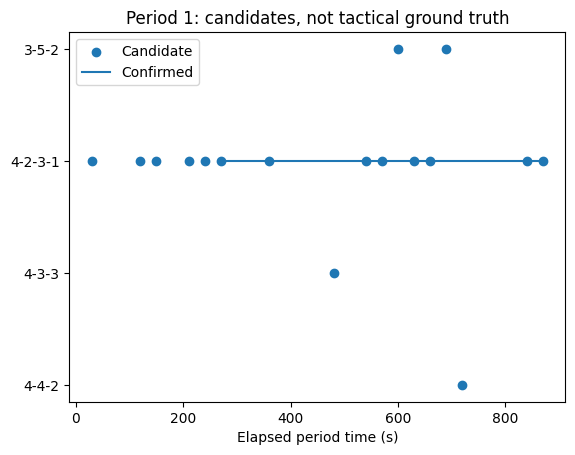

In [6]:
team['window']=(team.seconds//30).astype(int)
records=[]
for (period,window),g in team[team.team_in_possession.eq(871)].groupby(['period_id','window']):
    per_player=g.groupby('player_id').agg(cx=('cx','median'),cy=('cy','median'),n=('frame_id','size'))
    if len(per_player)!=10 or per_player.n.min()<50:continue
    fits=score_templates(-per_player[['cx','cy']].to_numpy())
    records.append(dict(period=period,window=window,label=fits[0][0],cost=fits[0][1],margin=fits[1][1]-fits[0][1]))
timeline=pd.DataFrame(records)
def confirm(sequence,n=3):
    current=None;candidate=None;count=0;result=[]
    for label in sequence:
        if not isinstance(label,str):candidate=None;count=0
        else:
            count=count+1 if label==candidate else 1;candidate=label
            if count>=n:current=candidate
        result.append(current)
    return result
for period,g in timeline.groupby('period'):
    g=g.set_index('window')
    g=g.reindex(range(int(g.index.min()),int(g.index.max())+1));g['confirmed']=confirm(g.label)
    display(g.head(12))
    labels=list(templates);mapping={v:i for i,v in enumerate(labels)}
    plt.scatter(g.index*30,g.label.map(mapping),label='Candidate');plt.plot(g.index*30,g.confirmed.map(mapping),label='Confirmed')
    plt.yticks(range(4),labels);plt.xlabel('Elapsed period time (s)');plt.title(f'Period {period}: candidates, not tactical ground truth');plt.legend();plt.show()